# 02 · ผล VALIDATION แบบละเอียด · expert01 + expert02
ใช้รุ่นที่ fit TRAIN เท่านั้น เพื่อดูผลบน VAL และเหตุผลการเลือกโมเดล
เล่มนี้ประเมินอย่างเดียว ไม่ fit หรือเปลี่ยนพารามิเตอร์ และไม่เปลี่ยนโมเดลเว็บ

แยก **usable** (landmark/feature ครบ) กับ **all reviewed** (รวมเฟรมที่ตรวจ landmark ไม่ได้)
เฟรมที่ตรวจไม่ได้มีผล `__unavailable__` และนับเป็นทายไม่สำเร็จ ไม่เติมว่าท่าถูก
คะแนนหลัก **clip-balanced Macro F1** ให้น้ำหนักรวมแต่ละคลิปเท่ากัน และเฉลี่ยทุกคลาสเท่ากัน

## 1.1 · โหลดเครื่องมือ

In [1]:
from pathlib import Path
import sys, json
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p/'training/src/training/combined_experts.py').exists())
if str(PROJECT/'training') not in sys.path:
    sys.path.insert(0, str(PROJECT/'training'))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from src.training import combined_experts as ce
ce.setup_plots()
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.executable)
print('Training directory:', ce.ROOT)
print('scikit-learn:', ce.sklearn.__version__)
WEB_BEFORE = ce.web_fingerprints()


Python: E:\Kamsuay\SawUAI\training\.venv\Scripts\python.exe
Training directory: E:\Kamsuay\SawUAI\training
scikit-learn: 1.9.1


## 1.2 · ระบุ run และยืนยันตัวเลือกที่ล็อกไว้

In [2]:
RUN = 'combined_experts_20261007_211339_512861'
REPORT = ce.ROOT/'reports'/RUN
MODEL_DIR = ce.ROOT/'models'/RUN
SPLIT = 'val'
MODEL_FOLDER = 'validation'
record = ce.read_json(REPORT/'training_record.json')
lock = ce.read_json(REPORT/'selection_lock.json')
assert lock['selection_sha256'] == ce.sha256(REPORT/'selection.json')
assert lock['test_used_for_selection'] is False
for task in ce.TASKS:
    expected = record['tasks'][task]['validation_model_sha256']
    assert ce.sha256(MODEL_DIR/MODEL_FOLDER/f'{task}.joblib') == expected
print('Run:',RUN)
print('Fit splits:', ["train"])
print('Evaluation split:',SPLIT)

Run: combined_experts_20261007_211339_512861
Fit splits: ['train']
Evaluation split: val


## 2.1 · จำนวนภาพที่ตรวจได้และตรวจไม่ได้
จำนวนแต่ละงานอาจซ้อนกันเพราะใช้ภาพเดียวกัน อย่ารวมเป็นจำนวนภาพต้นฉบับ
Coverage คือจำนวนที่ feature ครบ / จำนวนเฟรมที่ผู้ตรวจเลือกสำหรับงานนั้น

In [3]:
inventory = []
for dataset in sorted({s['dataset'] for s in ce.TASKS.values()}):
    usable = pd.read_csv(ce.DATA/dataset/f'{SPLIT}.csv')
    audit = pd.read_csv(ce.DATA/dataset/f'{SPLIT}_audit.csv')
    inventory.append(dict(dataset=dataset,reviewed_frames=len(audit),usable_frames=len(usable),
        excluded_frames=len(audit)-len(usable),clips=audit.clip_id.nunique(),coverage=len(usable)/len(audit)))
display(pd.DataFrame(inventory).round(4))

,dataset,reviewed_frames,usable_frames,excluded_frames,clips,coverage
0,bow_angle_float_body_proxy,108,83,25,11,0.7685
1,initial_grip_rightmost,66,52,14,11,0.7879
2,playing_posture_head_shoulder,258,258,0,7,1.0000


## 2.2 · ความหมายคะแนน
- **Accuracy:** สัดส่วนที่ทายถูก
- **Precision:** เมื่อแจ้งว่าผิด มีคำตอบจริงผิดกี่ส่วน
- **Recall:** จากภาพที่ผิดจริง ตรวจพบกี่ส่วน
- **F1:** รวม Precision และ Recall; Macro F1 เฉลี่ยทุกคลาสเท่ากัน
- **Clip-balanced:** น้ำหนักรวมต่อคลิปเท่ากัน ลดผลจากคลิปที่มีเฟรมมาก
- **Support:** จำนวนเฟรมในตารางปกติ; ในตารางถ่วงน้ำหนักคือผลรวมน้ำหนัก ไม่ใช่จำนวนเฟรม
Model support จาก predict_proba ยังไม่ใช่เปอร์เซ็นต์ความแม่นยำที่ปรับเทียบแล้ว

## 3.1 · ทำนายและบันทึกผลทุกงาน

In [4]:
results, rows_by_task, bundles = {}, {}, {}
for task in ce.TASKS:
    bundle = joblib.load(MODEL_DIR/MODEL_FOLDER/f'{task}.joblib')
    expected_fit = ['train','val'] if SPLIT=='test' else ['train']
    assert bundle['fit_splits'] == expected_fit
    result,rows = ce.evaluate_bundle(task,bundle,SPLIT,REPORT)
    results[task],rows_by_task[task],bundles[task] = result,rows,bundle
scores = ce.result_table(results)
display(scores.round(4))
scores.to_csv(REPORT/SPLIT/'summary_scores.csv',index=False,encoding='utf-8-sig')
ce.save_json(REPORT/SPLIT/'results.json',results)

,task,family,features,usable_frames,reviewed_frames,clips,usable_accuracy,usable_macro_f1,balanced_f1_usable,balanced_accuracy_all,balanced_f1_all,balanced_coverage
0,ก้มหน้า,random_forest,10,258,258,7,0.7016,0.6851,0.7072,0.7123,0.7072,1.0000
1,ไหล่เอียง,random_forest,10,258,258,7,0.8333,0.7938,0.7494,0.7618,0.7494,1.0000
2,จับคันชักตอนเริ่ม,random_forest,2,52,66,11,0.8462,0.8139,0.7320,0.6515,0.7486,0.7985
3,ควรปรับองศาการสี,decision_tree,4,83,108,11,0.8072,0.7966,0.8274,0.6910,0.7190,0.7606


## 3.2 · เปรียบเทียบคะแนน usable กับคะแนนรวมทั้งหมด
คะแนน usable บอกความสามารถตัวจำแนกเมื่อได้รับ feature ครบ
คะแนน all reviewed รวมปัญหา landmark ของ pipeline ด้วย จึงอาจต่ำกว่า
ตารางหลักไม่ซ่อนเฟรมที่โมเดลทายผิดหรือ landmark ไม่ครบ

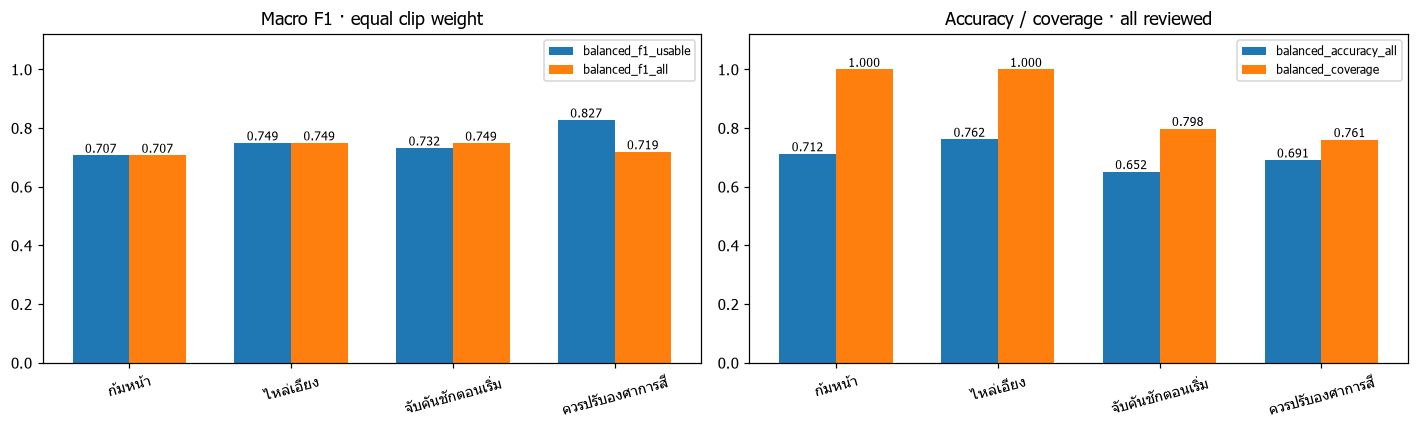

In [5]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
x = np.arange(len(scores)); width=.35
for ax,cols,title in [
    (axes[0],['balanced_f1_usable','balanced_f1_all'],'Macro F1 · equal clip weight'),
    (axes[1],['balanced_accuracy_all','balanced_coverage'],'Accuracy / coverage · all reviewed')]:
    for offset,col in enumerate(cols):
        bars=ax.bar(x+(offset-.5)*width,scores[col],width,label=col)
        ax.bar_label(bars,fmt='%.3f',fontsize=8)
    ax.set_xticks(x,scores.task,rotation=15); ax.set(ylim=(0,1.12),title=title); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(REPORT/SPLIT/'scores.png'); plt.show()

## 4.1 · Tree / Forest / Dummy และเหตุผลที่เลือก
Tree/Forest ฝึกจาก TRAIN เท่านั้น; Dummy ทายคลาสส่วนใหญ่จาก TRAIN
ตารางนี้เป็นคะแนน usable ที่ใช้เลือกครอบครัวโมเดล พร้อมช่องว่าง train–val
หาก train สูงแต่ val ต่ำ อาจ overfit หรือข้อมูลคน/คลิปต่างกัน

,task,family,selected,train_f1,cv_f1,val_f1,gap
0,ก้มหน้า,decision_tree,False,0.9756,0.7995,0.6687,0.3068
1,ก้มหน้า,random_forest,True,0.9908,0.7862,0.7072,0.2836
2,ก้มหน้า,dummy_majority,False,NaN,NaN,0.3670,NaN
3,ไหล่เอียง,decision_tree,False,0.8884,0.8199,0.6542,0.2342
4,ไหล่เอียง,random_forest,True,0.9059,0.7867,0.7494,0.1565
5,ไหล่เอียง,dummy_majority,False,NaN,NaN,0.4167,NaN
6,จับคันชักตอนเริ่ม,decision_tree,False,0.8606,0.7831,0.7320,0.1286
7,จับคันชักตอนเริ่ม,random_forest,True,0.8782,0.7942,0.7320,0.1462
8,จับคันชักตอนเริ่ม,dummy_majority,False,NaN,NaN,0.2593,NaN
9,ควรปรับองศาการสี,decision_tree,True,0.7593,0.7173,0.8274,-0.0681


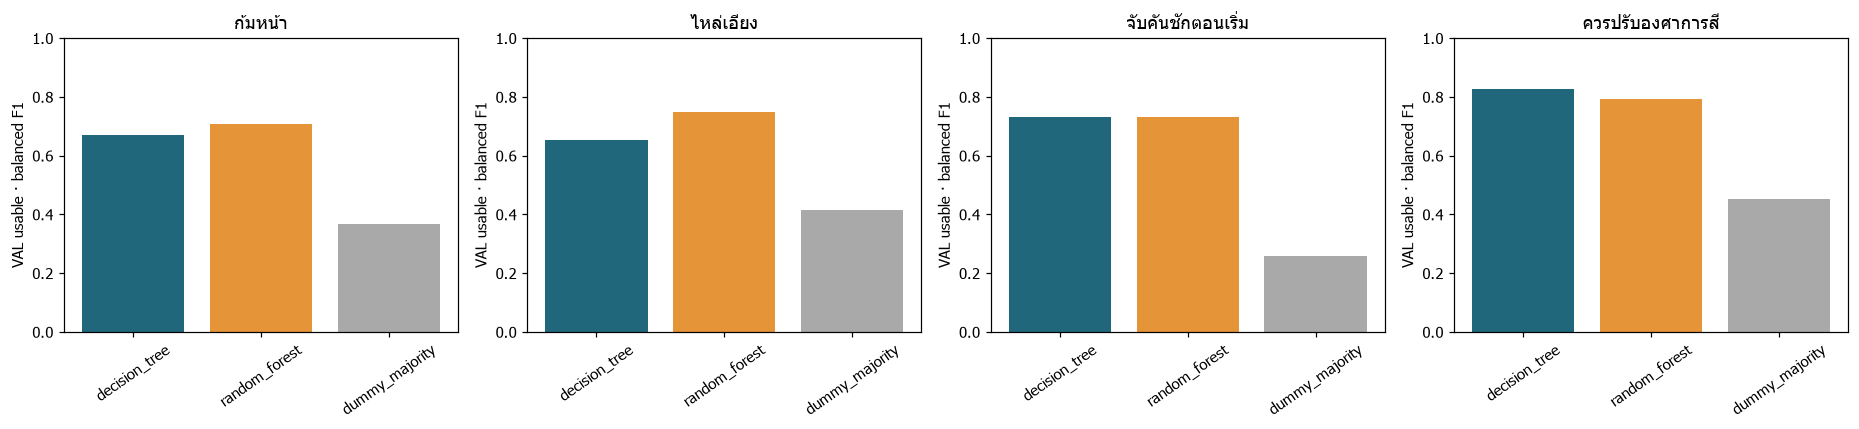

In [6]:
selection = ce.read_json(REPORT/'selection.json')
compare = []
for task,entry in selection.items():
    for candidate in entry['finalists']:
        candidate_bundle = joblib.load(MODEL_DIR/'validation/candidates'/f"{candidate['candidate_id']}.joblib")
        ce.evaluate_bundle(task,candidate_bundle,'val',REPORT,tag=candidate['family'])
        compare.append(dict(task=ce.TASKS[task]['title'],family=candidate['family'],
            selected=candidate['candidate_id']==entry['selected']['candidate_id'],
            train_f1=candidate['train']['clip_balanced_macro_f1'],cv_f1=candidate['cv']['clip_balanced_macro_f1'],
            val_f1=candidate['val']['clip_balanced_macro_f1'],
            gap=candidate['train']['clip_balanced_macro_f1']-candidate['val']['clip_balanced_macro_f1']))
    compare.append(dict(task=ce.TASKS[task]['title'],family='dummy_majority',selected=False,
        val_f1=entry['dummy_val']['clip_balanced_macro_f1']))
comparison = pd.DataFrame(compare)
display(comparison.round(4))
comparison.to_csv(REPORT/'val/model_comparison.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,4,figsize=(17,4))
for ax,(title,df) in zip(axes,comparison.groupby('task',sort=False)):
    ax.bar(df.family,df.val_f1,color=['#21677c','#e59437','#a9a9a9'])
    ax.set(title=title,ylim=(0,1),ylabel='VAL usable · balanced F1'); ax.tick_params(axis='x',rotation=35)
fig.tight_layout(); fig.savefig(REPORT/'val/comparison.png'); plt.show()

## 5 · รายละเอียดงาน ก้มหน้า
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.8759,0.6667,0.7571,180.0000
1,0.5041,0.7821,0.6131,78.0000
accuracy,0.7016,0.7016,0.7016,0.7016
macro avg,0.6900,0.7244,0.6851,258.0000
weighted avg,0.7635,0.7016,0.7136,258.0000


,precision,recall,f1-score,support
0,0.7642,0.7288,0.7460,4.0588
1,0.6482,0.6896,0.6683,2.9412
accuracy,0.7123,0.7123,0.7123,0.7123
macro avg,0.7062,0.7092,0.7072,7.0000
weighted avg,0.7154,0.7123,0.7134,7.0000


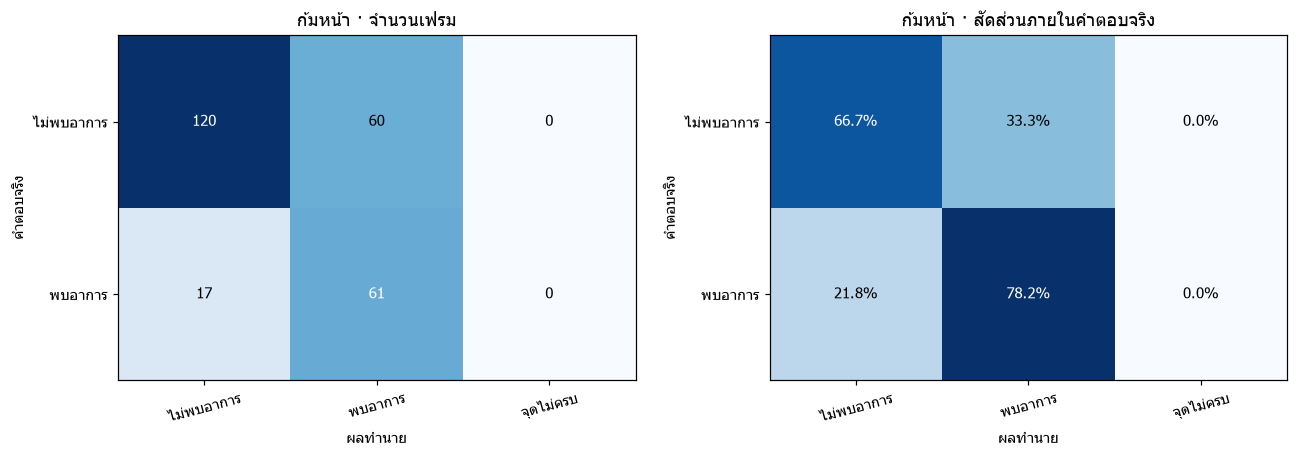

In [7]:
task = 'head_down'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ก้มหน้า: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,176.0,4.0,0.6932,0.6707,0.7042,0.7002,1.0,1.0
expert_02,82.0,3.0,0.7195,0.7123,0.7231,0.7163,1.0,1.0


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 125, '1': 51}",[],0.7002
1,expert_02,"{'0': 55, '1': 27}",[],0.7163


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
0,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,17,17,0.2353,16
6,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_02,28,28,0.4286,0
1,expert_01/playing_posture/E01_PP_correct_S01_T05.mp4.mp4,expert_01,98,98,0.5816,0
5,expert_02/playing_posture/E02_PP_head_down_S01_T01.mp4.mp4,expert_02,27,27,0.8519,27
4,expert_02/playing_posture/E02_PP_correct_S01_T03.mp4.mp4,expert_02,27,27,0.8889,0
2,expert_01/playing_posture/E01_PP_head_down_S01_T05.mp4.mp4,expert_01,35,35,1.0000,35
3,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T02.mp4.mp4,expert_01,26,26,1.0000,0


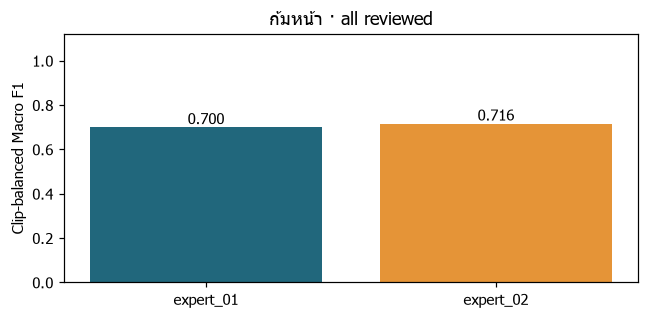

In [8]:
task = 'head_down'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ก้มหน้า · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน ไหล่เอียง
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.9820,0.8039,0.8841,204.0000
1,0.5604,0.9444,0.7034,54.0000
accuracy,0.8333,0.8333,0.8333,0.8333
macro avg,0.7712,0.8742,0.7938,258.0000
weighted avg,0.8938,0.8333,0.8463,258.0000


,precision,recall,f1-score,support
0,0.9683,0.6890,0.8051,5.0000
1,0.5483,0.9437,0.6936,2.0000
accuracy,0.7618,0.7618,0.7618,0.7618
macro avg,0.7583,0.8164,0.7494,7.0000
weighted avg,0.8483,0.7618,0.7733,7.0000


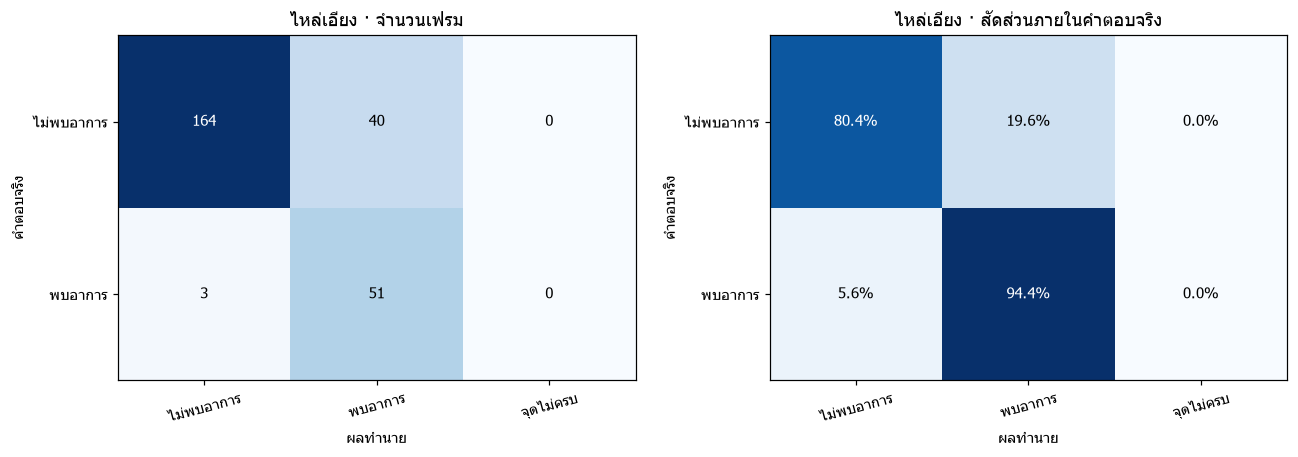

In [9]:
task = 'shoulder_tilt'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ไหล่เอียง: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,176.0,4.0,0.8523,0.7776,0.7402,0.7183,1.0,1.0
expert_02,82.0,3.0,0.7927,0.7889,0.7906,0.7859,1.0,1.0


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 150, '1': 26}",[],0.7183
1,expert_02,"{'0': 54, '1': 28}",[],0.7859


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
0,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,17,17,0.1765,0
4,expert_02/playing_posture/E02_PP_correct_S01_T03.mp4.mp4,expert_02,27,27,0.4074,0
1,expert_01/playing_posture/E01_PP_correct_S01_T05.mp4.mp4,expert_01,98,98,0.9184,0
3,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T02.mp4.mp4,expert_01,26,26,0.9231,26
2,expert_01/playing_posture/E01_PP_head_down_S01_T05.mp4.mp4,expert_01,35,35,0.9429,0
6,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_02,28,28,0.9643,28
5,expert_02/playing_posture/E02_PP_head_down_S01_T01.mp4.mp4,expert_02,27,27,1.0000,0


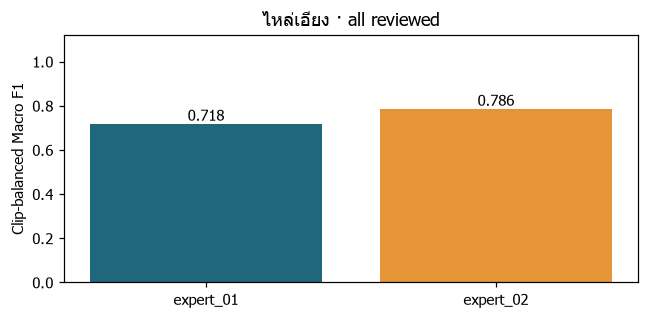

In [10]:
task = 'shoulder_tilt'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ไหล่เอียง · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน จับคันชักตอนเริ่ม
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
none,0.8788,0.6170,0.7250,47.0
grip_too_high,0.7500,1.0000,0.8571,9.0
grip_too_low,0.8571,0.6000,0.7059,10.0
micro avg,0.8462,0.6667,0.7458,66.0
macro avg,0.8286,0.7390,0.7627,66.0
weighted avg,0.8579,0.6667,0.7401,66.0


,precision,recall,f1-score,support
none,0.8322,0.5667,0.6742,7.0
grip_too_high,0.7792,1.0000,0.8759,2.0
grip_too_low,0.8276,0.6000,0.6957,2.0
micro avg,0.8159,0.6515,0.7245,11.0
macro avg,0.8130,0.7222,0.7486,11.0
weighted avg,0.8217,0.6515,0.7148,11.0


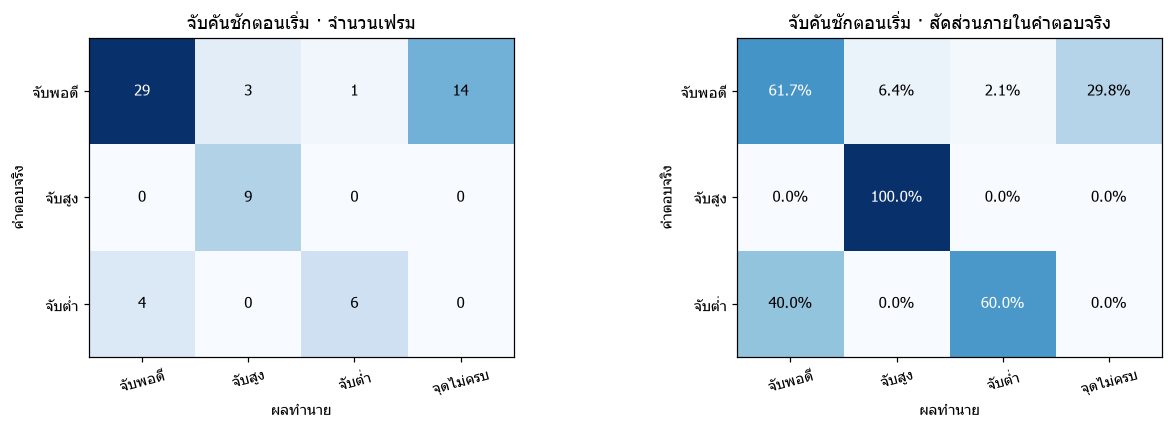

In [11]:
task = 'initial_grip'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · จับคันชักตอนเริ่ม: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,41.0,6.0,0.6829,0.8071,0.6389,0.7740,0.7561,0.7472
expert_02,25.0,5.0,0.6400,0.7146,0.6667,0.7348,0.8400,0.8600


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'none': 31, 'grip_too_high': 5, 'grip_too_low': 5}",[],0.7740
1,expert_02,"{'none': 16, 'grip_too_low': 5, 'grip_too_high': 4}",[],0.7348


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
2,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,4,1,0.0000,NaN
8,expert_02/playing_posture/E02_PP_correct_S01_T03.mp4.mp4,expert_02,6,3,0.3333,NaN
9,expert_02/playing_posture/E02_PP_head_down_S01_T01.mp4.mp4,expert_02,5,4,0.4000,NaN
1,expert_01/bow_hold/E01_BH_grip_too_low_S01_T02.mp4.mp4,expert_01,5,5,0.6000,NaN
7,expert_02/bow_hold/E02_BH_grip_too_low_S01_T02.mp4.mp4,expert_02,5,5,0.6000,NaN
5,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T02.mp4.mp4,expert_01,6,4,0.6667,NaN
3,expert_01/playing_posture/E01_PP_correct_S01_T05.mp4.mp4,expert_01,15,11,0.7333,NaN
4,expert_01/playing_posture/E01_PP_head_down_S01_T05.mp4.mp4,expert_01,6,5,0.8333,NaN
6,expert_02/bow_hold/E02_BH_grip_too_high_S01_T03.mp4.mp4,expert_02,4,4,1.0000,NaN
0,expert_01/bow_hold/E01_BH_grip_too_high_S01_T02.mp4.mp4,expert_01,5,5,1.0000,NaN


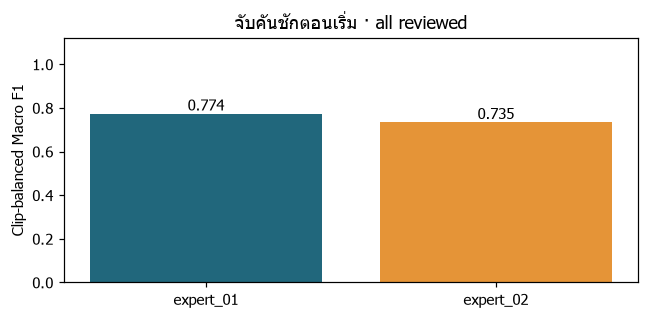

In [12]:
task = 'initial_grip'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='จับคันชักตอนเริ่ม · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน ควรปรับองศาการสี
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.7414,0.7288,0.7350,59.0
1,0.9600,0.4898,0.6486,49.0
micro avg,0.8072,0.6204,0.7016,108.0
macro avg,0.8507,0.6093,0.6918,108.0
weighted avg,0.8406,0.6204,0.6958,108.0


,precision,recall,f1-score,support
0,0.9217,0.7307,0.8152,9.1071
1,0.8255,0.5000,0.6228,1.8929
micro avg,0.9085,0.6910,0.7850,11.0000
macro avg,0.8736,0.6154,0.7190,11.0000
weighted avg,0.9051,0.6910,0.7821,11.0000


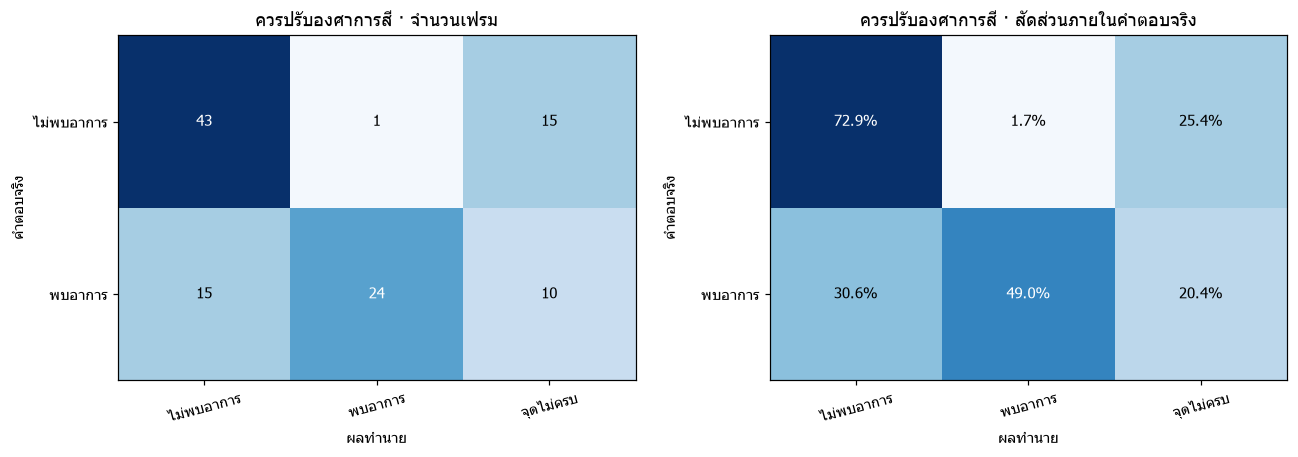

In [13]:
task = 'bow_error'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ควรปรับองศาการสี: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,55.0,5.0,0.6545,0.7530,0.6217,0.7557,0.7455,0.6633
expert_02,53.0,6.0,0.5849,0.6238,0.7488,0.6602,0.7925,0.8417


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 31, '1': 24}",[],0.7557
1,expert_02,"{'0': 28, '1': 25}",[],0.6602


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
1,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,4,1,0.2500,0
5,expert_02/bow_hold/E02_BH_bow_angle_wrong_S01_T04.mp4.mp4,expert_02,28,21,0.3929,25
8,expert_02/playing_posture/E02_PP_correct_S01_T03.mp4.mp4,expert_02,6,3,0.5000,0
9,expert_02/playing_posture/E02_PP_head_down_S01_T01.mp4.mp4,expert_02,5,4,0.6000,0
0,expert_01/bow_hold/E01_BH_bow_angle_wrong_S01_T02.mp4.mp4,expert_01,24,20,0.6250,24
4,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T02.mp4.mp4,expert_01,6,4,0.6667,0
2,expert_01/playing_posture/E01_PP_correct_S01_T05.mp4.mp4,expert_01,15,11,0.7333,0
3,expert_01/playing_posture/E01_PP_head_down_S01_T05.mp4.mp4,expert_01,6,5,0.8333,0
7,expert_02/bow_hold/E02_BH_grip_too_low_S01_T02.mp4.mp4,expert_02,5,5,1.0000,0
6,expert_02/bow_hold/E02_BH_grip_too_high_S01_T03.mp4.mp4,expert_02,4,4,1.0000,0


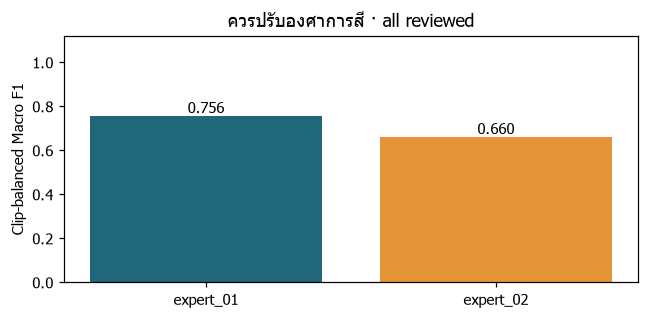

In [14]:
task = 'bow_error'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ควรปรับองศาการสี · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 6.1 · ตรวจสองอาการพร้อมกัน
Exact match คือทายก้มหน้าและไหล่เอียงถูกทั้งคู่ในเฟรมเดียวกัน
Joint recall คือภาพที่ผิดทั้งสองอาการแล้วตรวจพบทั้งสอง; หากไม่มีภาพดังกล่าวจะไม่มีค่าคะแนนนี้
จำนวนคลิปที่มีทั้งสองอาการสำคัญกว่าจำนวนเฟรมเพียงอย่างเดียว

In [15]:
joint=ce.posture_joint(SPLIT,rows_by_task,REPORT)
display(pd.DataFrame([joint]).round(4))

,frames,exact_match,clip_balanced_exact_match,jointly_positive_frames,jointly_positive_clips,both_symptoms_detected,joint_recall
0,258,0.5969,0.5707,0,0,0,None


## 6.2 · เปิดตัวอย่างที่ทายผิดหรือประเมินไม่ได้
ตารางแสดงคำตอบจริง/ผลทำนายและตำแหน่งไฟล์ ยังคงตัวอย่างเหล่านี้ไว้ในคะแนน
ภาพตัวอย่างเป็นการทบทวนผล ไม่ใช้แก้ค่าหลังเห็น TEST ในรอบนี้

In [16]:
errors=[]
for task,rows in rows_by_task.items():
    selected=rows.loc[~rows.is_correct,['frame_path','clip_id','expert','timestamp_s','truth','prediction','geometry_status']].copy()
    selected.insert(0,'task',task)
    errors.append(selected)
error_table=pd.concat(errors,ignore_index=True)
display(error_table.groupby(['task','truth','prediction']).size().rename('frames').reset_index())
display(error_table.head(20))
error_table.to_csv(REPORT/SPLIT/'all_errors.csv',index=False,encoding='utf-8-sig')

,task,truth,prediction,frames
0,bow_error,0,1,1
1,bow_error,0,__unavailable__,15
2,bow_error,1,0,15
3,bow_error,1,__unavailable__,10
4,head_down,0,1,60
5,head_down,1,0,17
6,initial_grip,grip_too_low,none,4
7,initial_grip,none,__unavailable__,14
8,initial_grip,none,grip_too_high,3
9,initial_grip,none,grip_too_low,1


,task,frame_path,clip_id,expert,timestamp_s,truth,prediction,geometry_status
0,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,0.000000,1,0,ready
1,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,0.511867,1,0,ready
2,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,1.008133,1,0,ready
3,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,1.519900,1,0,ready
4,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,2.016467,1,0,ready
5,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,2.528000,1,0,ready
6,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,3.024033,1,0,ready
7,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,3.984000,1,0,ready
8,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,4.496400,1,0,ready
9,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T04.mp4.mp4,expert_01,4.992033,1,0,ready


**head_down** · expert_01 · 0.00s · จริง `1` / ทำนาย `0`

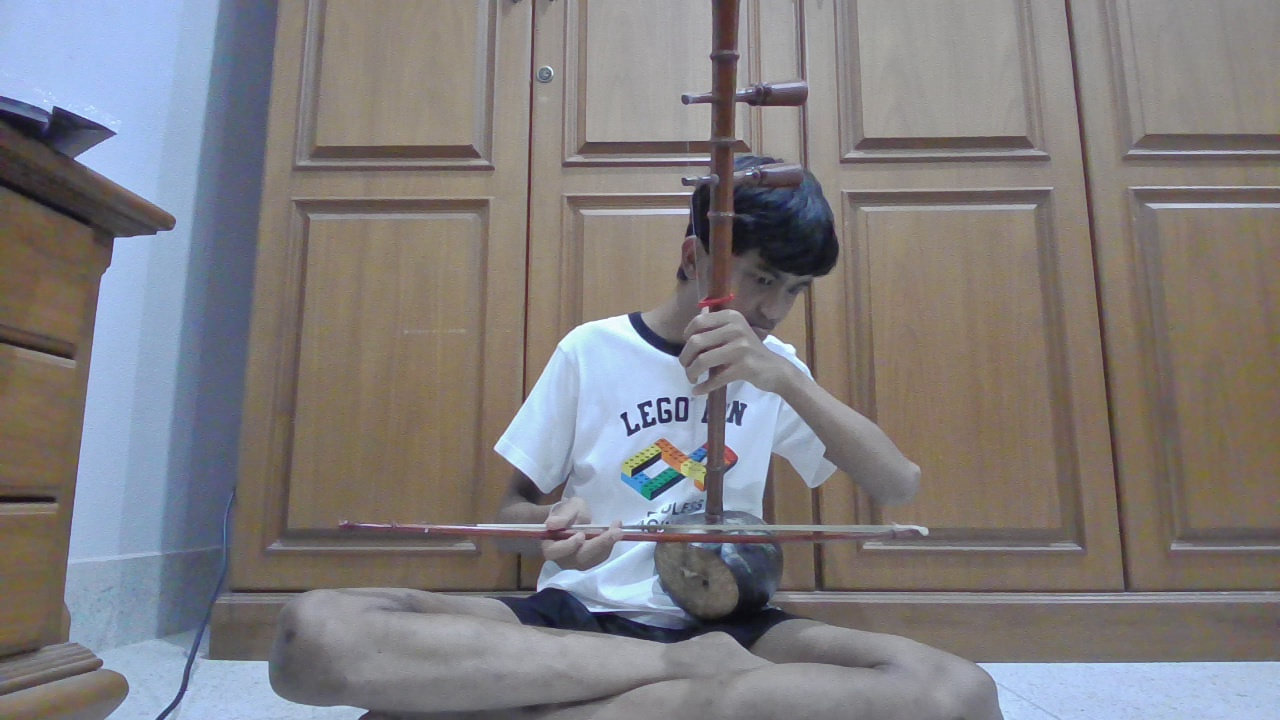

**head_down** · expert_01 · 12.00s · จริง `0` / ทำนาย `1`

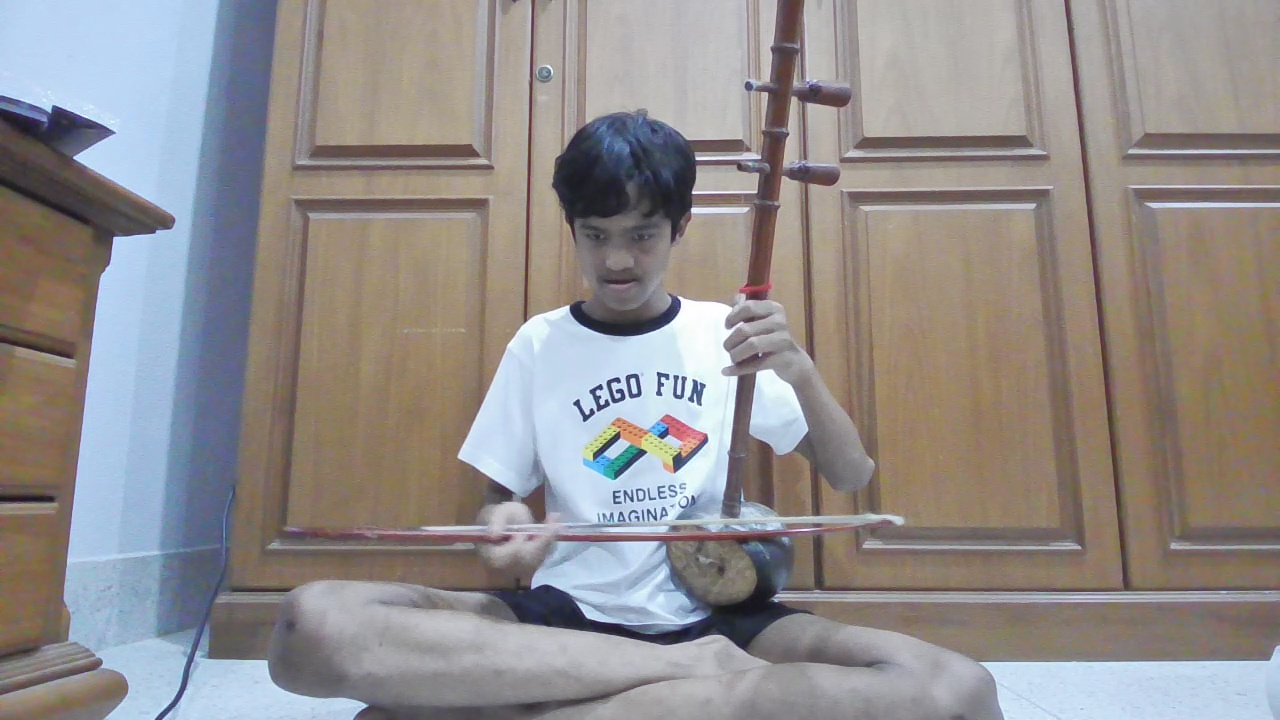

**shoulder_tilt** · expert_01 · 1.01s · จริง `0` / ทำนาย `1`

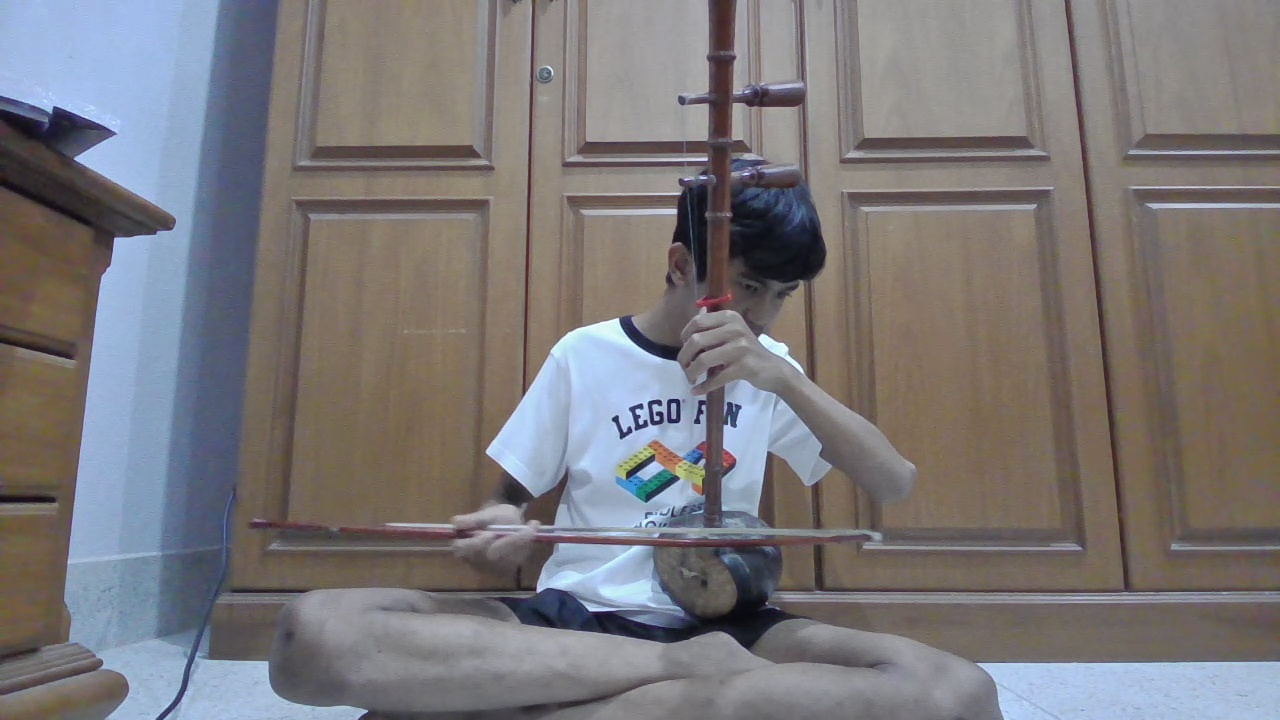

**shoulder_tilt** · expert_01 · 24.02s · จริง `0` / ทำนาย `1`

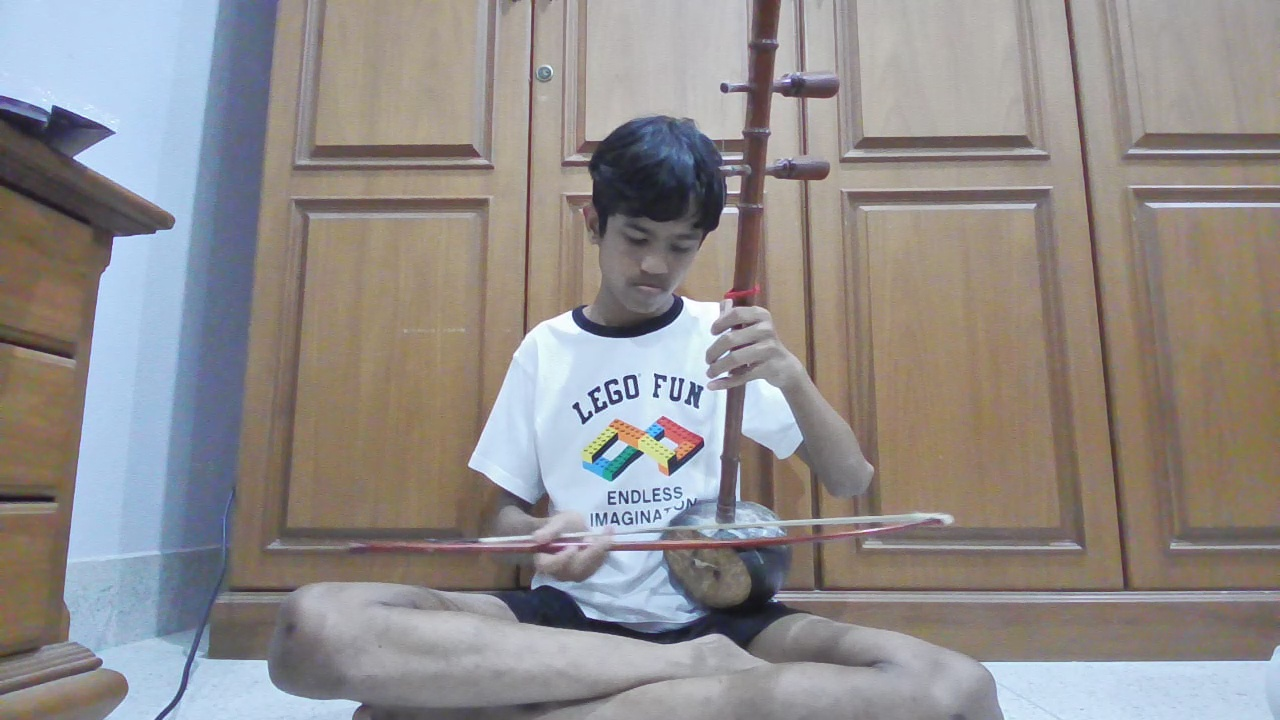

**initial_grip** · expert_01 · 3.02s · จริง `grip_too_low` / ทำนาย `none`

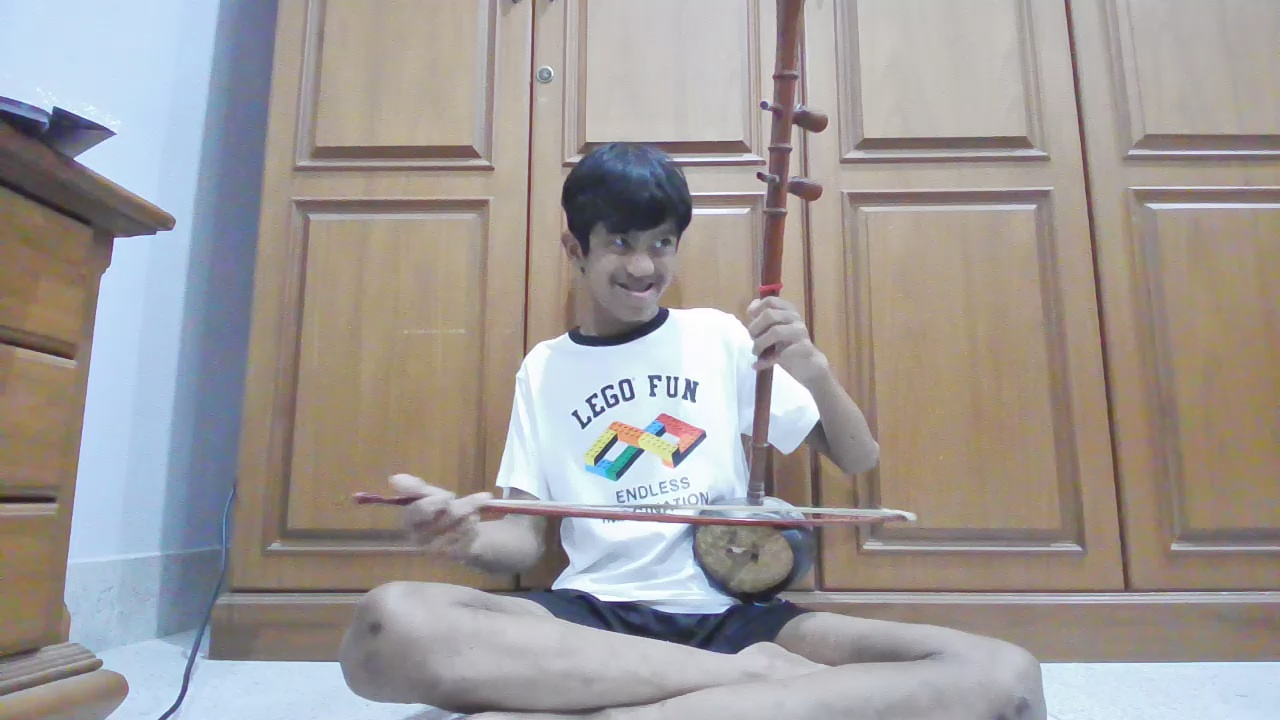

**initial_grip** · expert_01 · 3.98s · จริง `none` / ทำนาย `__unavailable__`

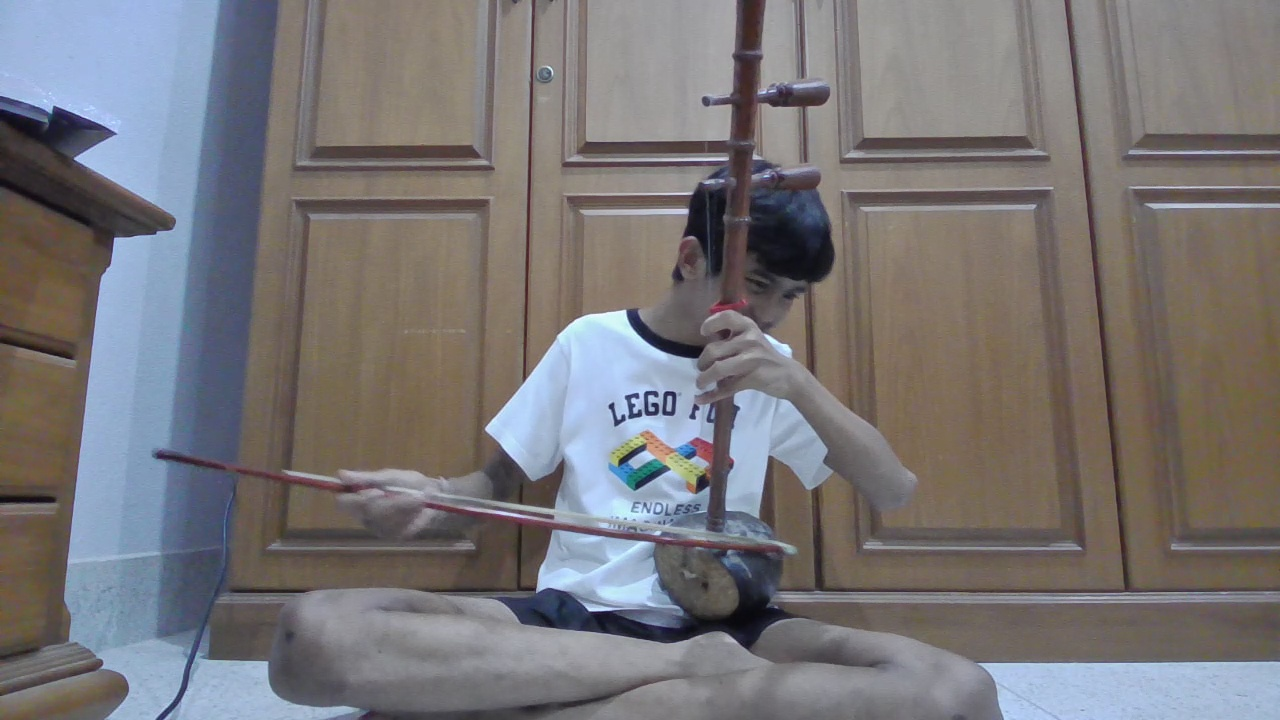

**bow_error** · expert_01 · 0.00s · จริง `1` / ทำนาย `0`

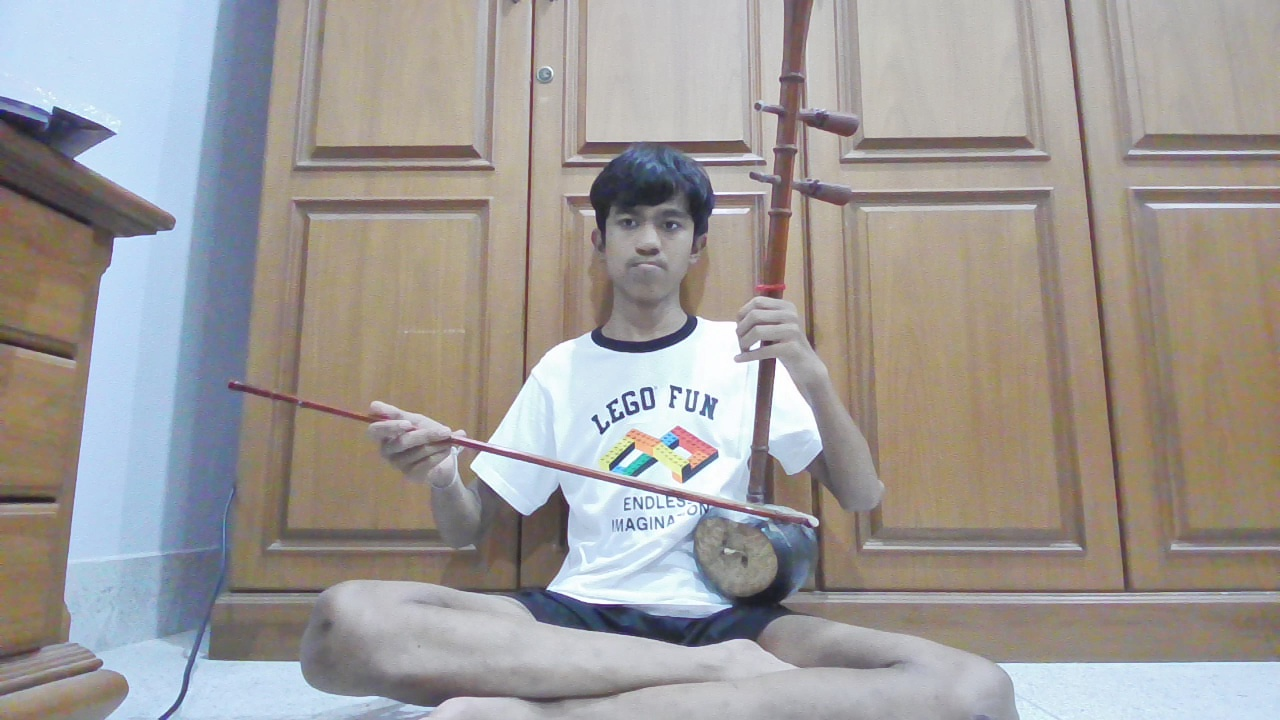

**bow_error** · expert_02 · 0.00s · จริง `1` / ทำนาย `__unavailable__`

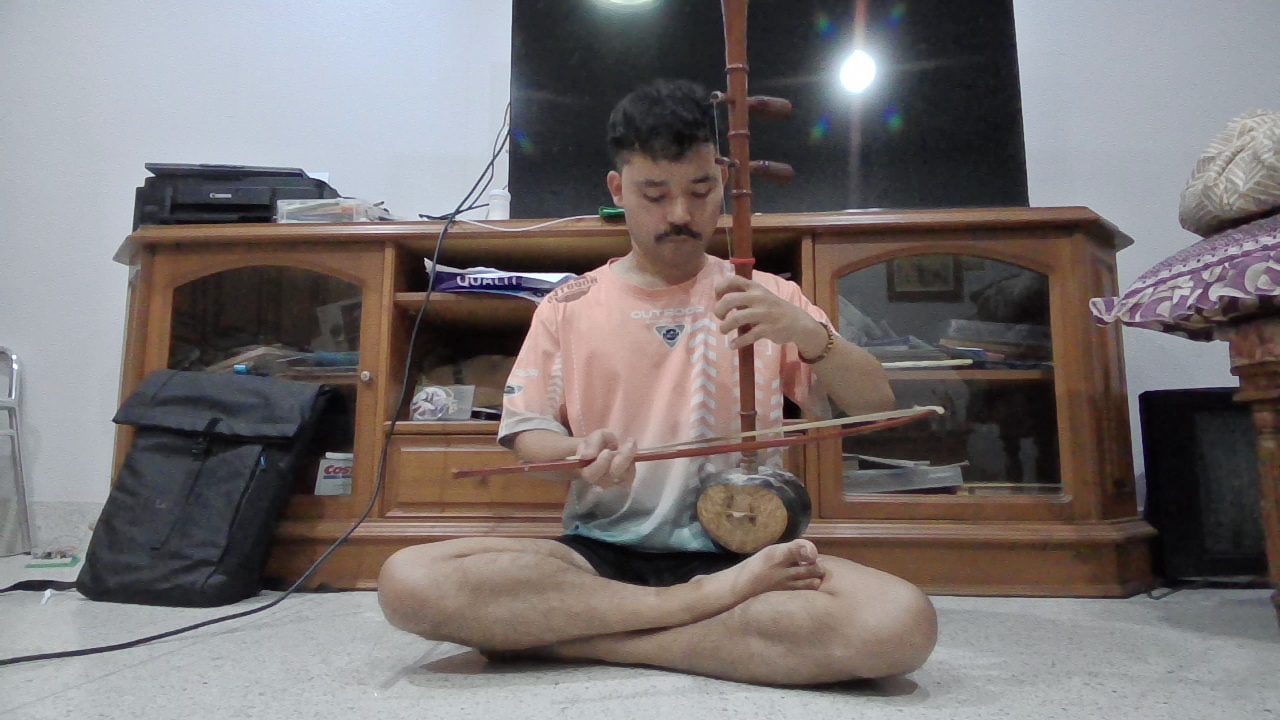

In [17]:
for task in ce.TASKS:
    examples=error_table.loc[error_table.task==task].drop_duplicates('clip_id').head(2)
    for _,row in examples.iterrows():
        display(Markdown(f"**{task}** · {row.expert} · {row.timestamp_s:.2f}s · จริง `{row.truth}` / ทำนาย `{row.prediction}`"))
        image=ce.ROOT/row.frame_path
        if image.exists(): display(Image(filename=str(image),width=440))

## 8.1 · สรุปผลและข้อจำกัด
อ่านทั้ง F1/Recall รายคลาส ผลรายคน Coverage และตัวอย่างผิดควบคู่กัน
การตรวจคันชักเป็นการทดลองจากร่างกาย; ยังไม่มีข้อมูลผู้เล่นคนที่สามหรือกล้อง/สถานที่ใหม่ที่กันไว้ทั้งคน
ไม่มีการนำรุ่นนี้ไปใช้เว็บอัตโนมัติ และคะแนนนี้ยังไม่รวม temporal smoothing/uncertainty guard ของเว็บ

In [18]:
lines=[]
for task,r in results.items():
    m=r['all_reviewed']; u=r['conditional']
    lines.append(f"- **{ce.TASKS[task]['title']}**: {r['family']}, F1 แบบคลิปเท่ากันเมื่อจุดครบ **{u['clip_balanced_macro_f1']:.3f}**, รวมจุดไม่ครบ **{m['clip_balanced_macro_f1']:.3f}**, coverage **{m['clip_balanced_coverage']:.1%}**, {m['frames']} เฟรม / {m['clips']} คลิป")
display(Markdown('\n'.join(lines)))
assert WEB_BEFORE == ce.web_fingerprints(), 'Web model changed during this run'
print('Web model unchanged: verified')
print('Report directory:',REPORT/SPLIT)

- **ก้มหน้า**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.707**, รวมจุดไม่ครบ **0.707**, coverage **100.0%**, 258 เฟรม / 7 คลิป
- **ไหล่เอียง**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.749**, รวมจุดไม่ครบ **0.749**, coverage **100.0%**, 258 เฟรม / 7 คลิป
- **จับคันชักตอนเริ่ม**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.732**, รวมจุดไม่ครบ **0.749**, coverage **79.8%**, 66 เฟรม / 11 คลิป
- **ควรปรับองศาการสี**: decision_tree, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.827**, รวมจุดไม่ครบ **0.719**, coverage **76.1%**, 108 เฟรม / 11 คลิป

Web model unchanged: verified
Report directory: E:\Kamsuay\SawUAI\training\reports\combined_experts_20261007_211339_512861\val


## วิเคราะห์ผล Validation และเหตุผลการเลือก

คะแนนต่อไปนี้เป็น **clip-balanced Macro F1 บน usable frames** ซึ่งใช้ตัดสินตัวเลือก ส่วนผลรวมเฟรมที่ landmark ไม่ครบอยู่ในตารางและ confusion matrix ด้านบน

### ก้มหน้า

random_forest · `posture_10` · `{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 150}` · `clip_class_balanced`

Tree VAL F1 **0.669**, Forest **0.707**, Dummy **0.367** → เลือกครอบครัวที่ VAL F1 สูงกว่า

Selected TRAIN F1 **0.991**, CV **0.786**, VAL **0.707**, ช่องว่าง TRAIN−VAL **0.284**; ช่องว่างมากชี้ว่าคะแนนบนข้อมูลที่เคยเรียนยังสูงกว่าคลิปที่กันไว้

### ไหล่เอียง

random_forest · `posture_10` · `{'max_depth': 3, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 150}` · `clip_class_balanced`

Tree VAL F1 **0.654**, Forest **0.749**, Dummy **0.417** → เลือกครอบครัวที่ VAL F1 สูงกว่า

Selected TRAIN F1 **0.906**, CV **0.787**, VAL **0.749**, ช่องว่าง TRAIN−VAL **0.157**; ช่องว่างมากชี้ว่าคะแนนบนข้อมูลที่เคยเรียนยังสูงกว่าคลิปที่กันไว้

### จับคันชักตอนเริ่ม

random_forest · `body_2` · `{'max_depth': 6, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 150}` · `clip_class_balanced`

Tree VAL F1 **0.732**, Forest **0.732**, Dummy **0.259** → VAL F1 เท่ากัน จึงเลือกตัวที่ TRAIN CV สูงกว่า

Selected TRAIN F1 **0.878**, CV **0.794**, VAL **0.732**, ช่องว่าง TRAIN−VAL **0.146**; ช่องว่างมากชี้ว่าคะแนนบนข้อมูลที่เคยเรียนยังสูงกว่าคลิปที่กันไว้

Feature 2 ตัวได้ TRAIN CV สูงสุด **0.794**, 4 ตัว **0.794**; feature เพิ่มไม่ได้รับประกันว่าทายคลิปใหม่ดีขึ้น

### ควรปรับองศาการสี

decision_tree · `body_4` · `{'max_depth': 3, 'min_samples_leaf': 10}` · `clip_equal`

Tree VAL F1 **0.827**, Forest **0.792**, Dummy **0.453** → เลือกครอบครัวที่ VAL F1 สูงกว่า

Selected TRAIN F1 **0.759**, CV **0.717**, VAL **0.827**, ช่องว่าง TRAIN−VAL **-0.068**; ช่องว่างมากชี้ว่าคะแนนบนข้อมูลที่เคยเรียนยังสูงกว่าคลิปที่กันไว้